In [1]:
!pip install albumentations

In [2]:
import os
import random
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import cv2
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

import torch
import torch.nn as nn
import torch.optim as optim
from torch.cuda.amp import autocast, GradScaler

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
import shutil

import albumentations as A
from albumentations.pytorch import ToTensorV2
import torchvision.models as models

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import cohen_kappa_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.utils import resample
from tqdm.auto import tqdm
import json

from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import numpy as np

In [3]:
def set_seed(seed=42):
    """Set the seed for reproducability"""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)
SEED = 42

**Name of whoever's running**

In [4]:
name = "aveera"
os.environ['TORCH_HOME'] = f'/data/{name}/torch_cache'

**Exploring the dataset**

In [5]:
train_df = pd.read_csv(f"/data/{name}/aptos2019-blindness-detection/train.csv")
folder = f"/data/{name}/aptos2019-blindness-detection/train_images"

print(train_df.head(15))
print(len(os.listdir(folder)))

         id_code  diagnosis
0   000c1434d8d7          2
1   001639a390f0          4
2   0024cdab0c1e          1
3   002c21358ce6          0
4   005b95c28852          0
5   0083ee8054ee          4
6   0097f532ac9f          0
7   00a8624548a9          2
8   00b74780d31d          2
9   00cb6555d108          1
10  00cc2b75cddd          0
11  00e4ddff966a          2
12  00f6c1be5a33          0
13  0104b032c141          3
14  0124dffecf29          1
3662


**We copy the image folder to local disk once; every epoch after that reads from local SSD instead of over the network.**

In [6]:
DRIVE_IMAGE_DIR = f"/data/{name}/aptos2019-blindness-detection/train_images"

**Displaying 3 images from each class of DR**

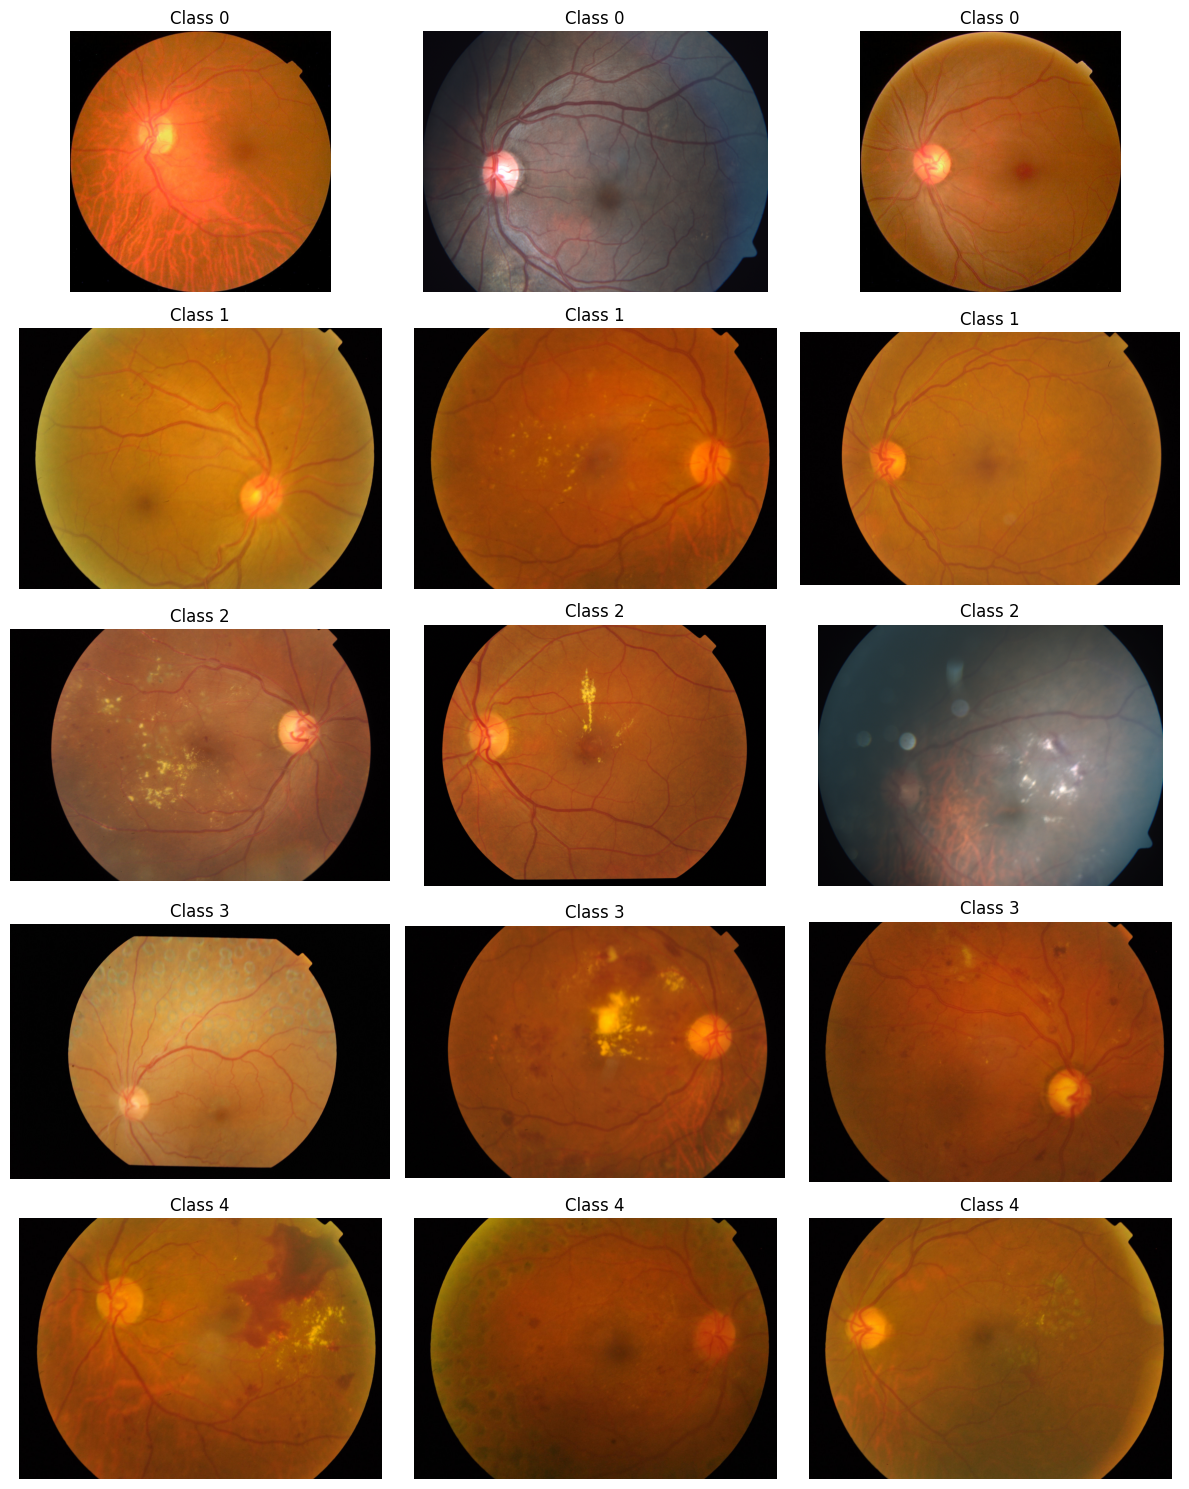

In [7]:
classes = sorted(train_df['diagnosis'].unique())

fig, axes = plt.subplots(len(classes), 3, figsize=(12, 15))

for row, cls in enumerate(classes):

    # get 3 samples from this class
    samples = train_df[train_df['diagnosis'] == cls].sample(3)

    for col, (_, sample) in enumerate(samples.iterrows()):

        img_path = os.path.join(DRIVE_IMAGE_DIR, sample['id_code'] + ".png")
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        axes[row, col].imshow(img)
        axes[row, col].set_title(f"Class {cls}")
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

**The dataset is split 70/10/20 into train, test and validation set using stratified sampling to preserve the original class distribution.**

In [8]:
train_df["image_path"] = train_df["id_code"].apply(lambda x: os.path.join(DRIVE_IMAGE_DIR, x + ".png"))

full_df = pd.read_csv(f"/data/{name}/aptos2019-blindness-detection/train.csv")
full_df["image_path"] = full_df["id_code"].apply(lambda x: os.path.join(DRIVE_IMAGE_DIR, x + ".png"))

train_val_df, test_df = train_test_split(
    full_df, test_size=0.20, stratify=full_df["diagnosis"], random_state=42
)
train_df, val_df = train_test_split(
    train_val_df, test_size=0.125, stratify=train_val_df["diagnosis"], random_state=42
)
print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

Train: 2562 | Val: 367 | Test: 733


**Printing training, test and validation set lengths**

In [9]:
print(train_df["diagnosis"].value_counts())
print(val_df["diagnosis"].value_counts())
print(test_df["diagnosis"].value_counts())

diagnosis
0    1263
2     699
1     259
4     206
3     135
Name: count, dtype: int64
diagnosis
0    181
2    100
1     37
4     30
3     19
Name: count, dtype: int64
diagnosis
0    361
2    200
1     74
4     59
3     39
Name: count, dtype: int64


**Oversampling the training set only**

In [10]:
print("Class distribution BEFORE oversampling:")
print(train_df["diagnosis"].value_counts().sort_index())

class_counts = train_df["diagnosis"].value_counts()
multipliers = {0: 1, 1: 5, 2: 2, 3: 9, 4: 6}

oversampled_dfs = []
for label, factor in multipliers.items():
    class_subset = train_df[train_df["diagnosis"] == label]
    target_count = len(class_subset) * factor
    n_needed = target_count - len(class_subset)
    if n_needed <= 0:
        oversampled_subset = class_subset
    else:
        extra = class_subset.sample(n=n_needed, replace=True, random_state=42)
        oversampled_subset = pd.concat([class_subset, extra])
    oversampled_dfs.append(oversampled_subset)

train_df = pd.concat(oversampled_dfs).sample(frac=1, random_state=42).reset_index(drop=True)

print("\nClass distribution AFTER oversampling:")
print(train_df["diagnosis"].value_counts().sort_index())

Class distribution BEFORE oversampling:
diagnosis
0    1263
1     259
2     699
3     135
4     206
Name: count, dtype: int64

Class distribution AFTER oversampling:
diagnosis
0    1263
1    1295
2    1398
3    1215
4    1236
Name: count, dtype: int64


**Graphs of before and after of oversampling**

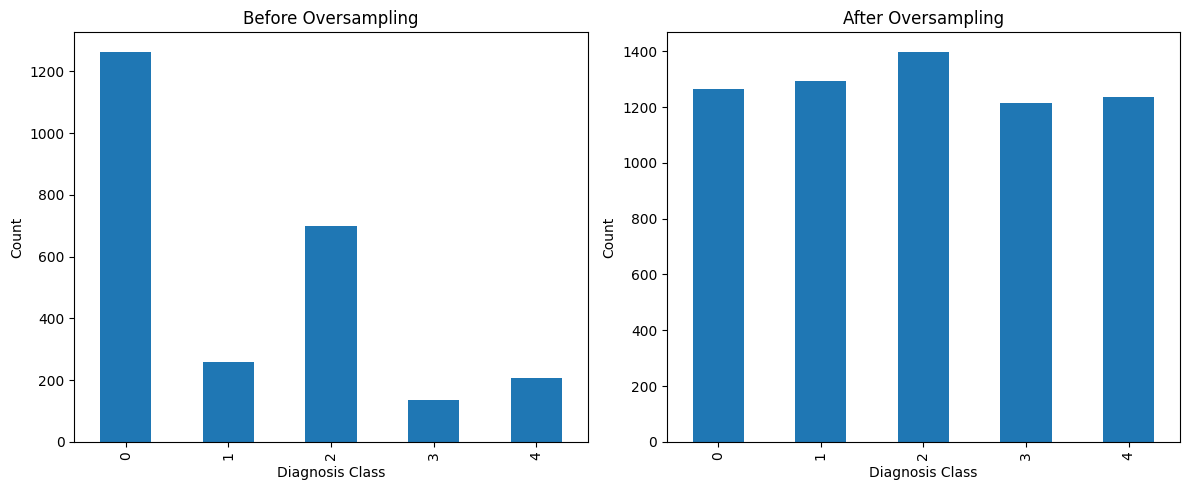

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
class_counts.sort_index().plot(kind='bar', ax=axes[0], title='Before Oversampling')
train_df["diagnosis"].value_counts().sort_index().plot(kind='bar', ax=axes[1], title='After Oversampling')
for ax in axes:
    ax.set_xlabel('Diagnosis Class')
    ax.set_ylabel('Count')
plt.tight_layout()
plt.show()

**APTOS 2019 Image preprocessing**

In [12]:
def crop_image_from_gray(img, tol=7):
    gray_img = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    mask = gray_img > tol

    check_shape = img[:,:,0][np.ix_(mask.any(1), mask.any(0))].shape[0]
    if check_shape == 0: 
        return img 
    else:
        img1 = img[:,:,0][np.ix_(mask.any(1), mask.any(0))]
        img2 = img[:,:,1][np.ix_(mask.any(1), mask.any(0))]
        img3 = img[:,:,2][np.ix_(mask.any(1), mask.any(0))]
        img = np.stack([img1, img2, img3], axis=-1)
    return img

def circle_crop(img, sigmaX=30):
    img = crop_image_from_gray(img)              

    height, width, depth = img.shape
    x = int(width / 2)
    y = int(height / 2)
    r = np.amin((x, y))

    circle_img = np.zeros((height, width), np.uint8)
    cv2.circle(circle_img, (x, y), int(r), 1, thickness=-1)
    img = cv2.bitwise_and(img, img, mask=circle_img)
    img = crop_image_from_gray(img)
    
    # Ben Graham's local illumination subtraction
    img = cv2.addWeighted(img, 4, cv2.GaussianBlur(img, (0, 0), sigmaX), -4, 128)
    return img

**Running preprocessing techniques for images**

In [13]:
CROPPED_IMAGE_DIR = f"/data/{name}/aptos2019-blindness-detection/adjusted_gce_clahe_images"
os.makedirs(CROPPED_IMAGE_DIR, exist_ok=True)

all_paths = pd.concat([train_df, val_df, test_df])["image_path"].unique()

for path in tqdm(all_paths, desc="Precomputing crops"):
    fname = os.path.basename(path)
    out_path = os.path.join(CROPPED_IMAGE_DIR, fname)
    if os.path.exists(out_path):
        continue
        
    img = cv2.imread(path) 
    green_channel = img[:, :, 1] # Extract Green channel

    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced_green = clahe.apply(green_channel) 

    bgr_enhanced = cv2.merge([enhanced_green, enhanced_green, enhanced_green]) # Merge into a clean 3-channel layout 

    rgb_enhanced = cv2.cvtColor(bgr_enhanced, cv2.COLOR_BGR2RGB)

    resized_img = cv2.resize(rgb_enhanced, (224, 224), interpolation=cv2.INTER_CUBIC)# Resize the image
    
    Image.fromarray(resized_img).save(out_path)

**APTOS dataset class**

In [14]:
class APTOSDataset(Dataset):

    def __init__(self, dataframe, transform=None, cropped_dir=CROPPED_IMAGE_DIR):
        self.df = dataframe
        self.transform = transform
        self.cropped_dir = cropped_dir

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.iloc[idx]["image_path"]
        label = self.df.iloc[idx]["diagnosis"]

        fname = os.path.basename(img_path)
        image = np.array(Image.open(os.path.join(self.cropped_dir, fname)).convert("RGB"))

        if self.transform:
            image = self.transform(image=image)["image"]

        return image, label

**Defining the augmentation transforms.**

**Training transforms**

In [15]:
train_transforms = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    
    # 360-degree rotation 
    A.Rotate(limit=180, p=0.5, border_mode=0), 
    
    A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=0.5),
    
    A.HueSaturationValue(hue_shift_limit=10, sat_shift_limit=15, val_shift_limit=10, p=0.5),
    
    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),
    ToTensorV2()
])


**Validation and test transforms**

In [16]:
val_transforms = A.Compose([
    A.Resize(224,224),
    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),
    ToTensorV2()
])

**Creating APTOS Datasets for train, validation and test set**

In [17]:
train_dataset = APTOSDataset(train_df, transform=train_transforms)
val_dataset = APTOSDataset(val_df, transform=val_transforms)
test_dataset = APTOSDataset(test_df, transform=val_transforms)

print(len(train_dataset))
print(len(val_dataset))
print(len(test_dataset))

6407
367
733


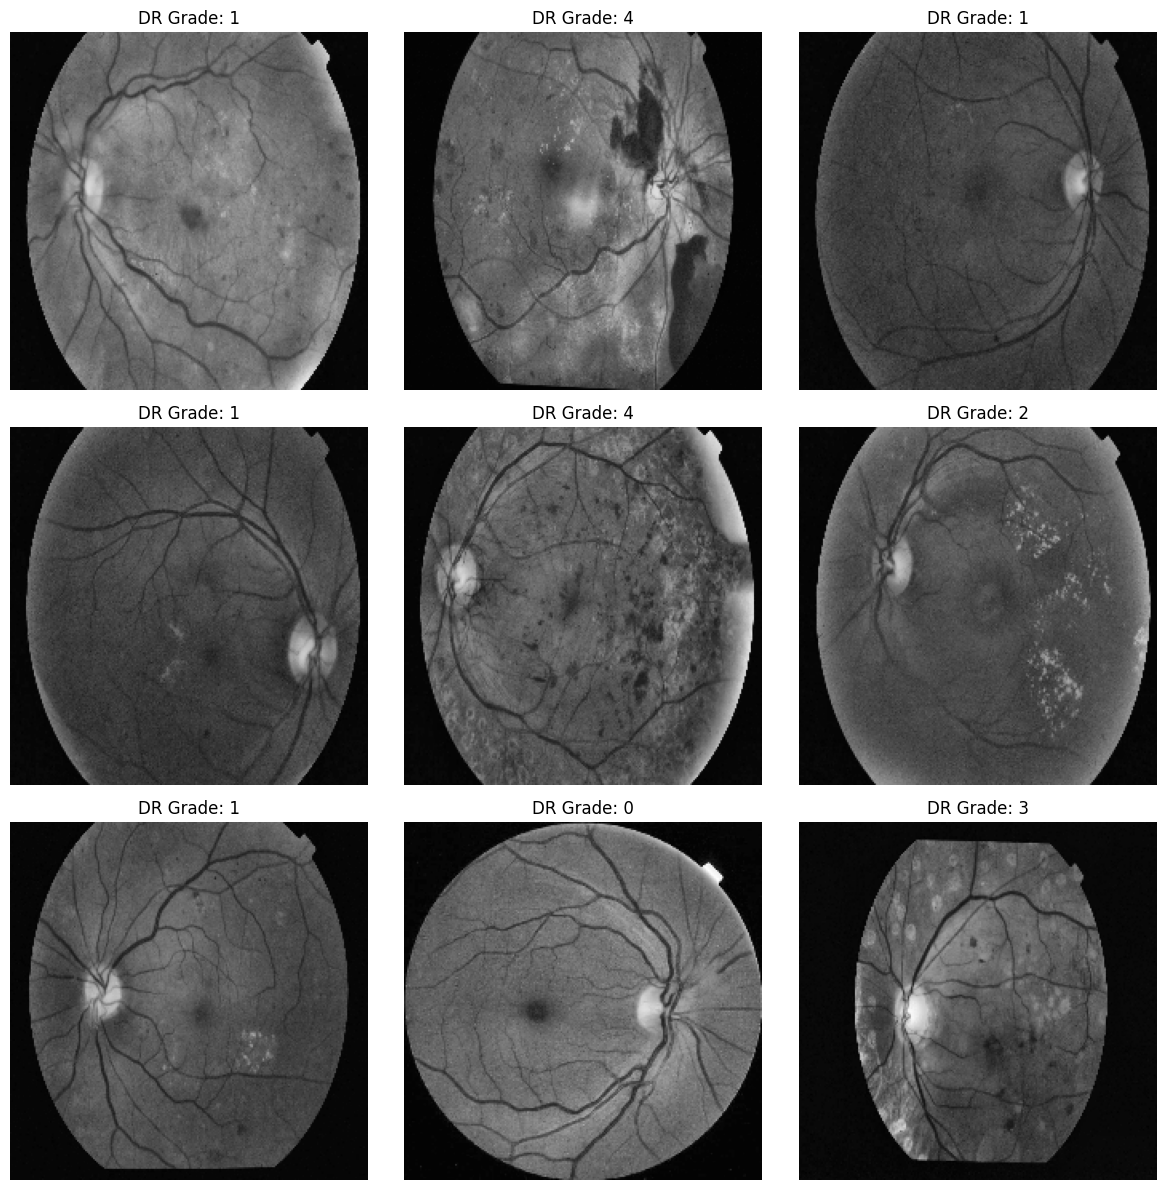

In [18]:
preprocessed_dataset = APTOSDataset(train_df,transform=None)

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for i, ax in enumerate(axes.flat):

    image, label = preprocessed_dataset[i]

    ax.imshow(image)
    ax.set_title(f"DR Grade: {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()

**A visual display of some of our augmentations being applied to the images**

In [19]:
duplicated_paths = train_df["image_path"][train_df["image_path"].duplicated(keep=False)]
sample_path = duplicated_paths.iloc[0]
sample_indices = train_df.index[train_df["image_path"] == sample_path].tolist()

print(f"This image appears {len(sample_indices)} times in train_df due to oversampling")

outputs = [train_dataset[idx][0] for idx in sample_indices]
diffs = [not torch.equal(outputs[0], o) for o in outputs[1:]]
print(f"Differed from the first copy in {sum(diffs)}/{len(diffs)} of the other duplicate rows")

This image appears 3 times in train_df due to oversampling
Differed from the first copy in 2/2 of the other duplicate rows


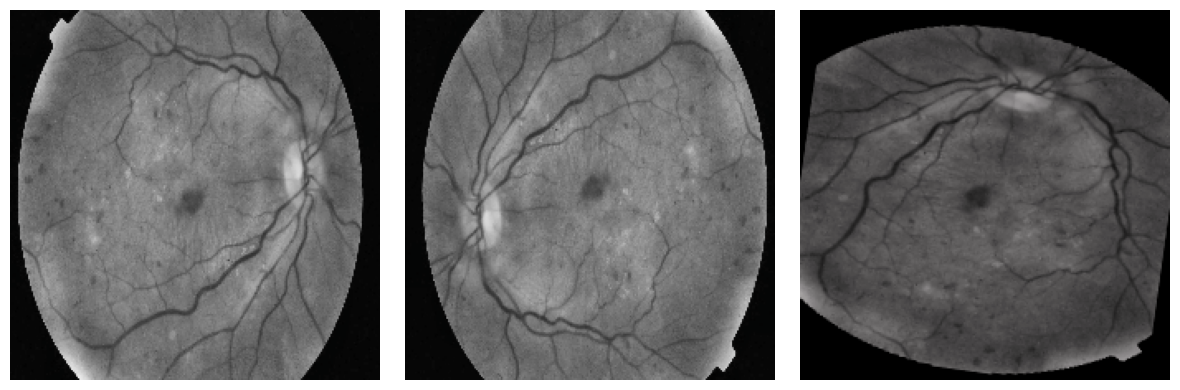

In [20]:
n = len(sample_indices)
ncols = min(n, 5)
nrows = (n // ncols)  

fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 4*nrows))
axes = np.atleast_1d(axes).flatten()

for ax, idx in zip(axes, sample_indices):
    img_tensor, _ = train_dataset[idx]
    img_np = img_tensor.permute(1, 2, 0).numpy()
    img_np = img_np * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
    img_np = np.clip(img_np, 0, 1)
    ax.imshow(img_np)
    ax.axis("off")

for ax in axes[n:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

**Creating train, validation and test loaders**

In [21]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=4,
    pin_memory=True,
    persistent_workers=True,
    drop_last=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
    persistent_workers=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
    persistent_workers=False
)

**Grabbing the images and labels of the training images from our train loader**

In [22]:
images, labels = next(iter(train_loader))

print(images.shape)
print(labels.shape)

torch.Size([32, 3, 224, 224])
torch.Size([32])


**Setting the device**

In [23]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

# Lets cuDNN pick the fastest conv algorithms since our input size (224x224) is fixed
torch.backends.cudnn.benchmark = True

cuda


In [24]:
def compute_qwk(y_true, y_pred):
    """Compute QWK"""
    return cohen_kappa_score(y_true, y_pred, weights="quadratic")

# **ResNet50**

**Loading pretrained ResNet50 Model**

In [25]:
model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)

num_features = model.fc.in_features

model.fc = nn.Sequential(
    nn.Dropout(0.5), # Randomly turns off 50% of the neural connections during training. Prevents overfitting.
    nn.Linear(num_features, 5) # Takes 2048 features and maps them to 5 classes to predict the 5 classes of DR.
)

model = model.to(device)

**Skipping if ResNet50 weights already exist**

In [ ]:
drive_model_dir = f"/data/{name}/models"
os.makedirs(drive_model_dir, exist_ok=True)
checkpoint_path = os.path.join(drive_model_dir, "resnet50_best_model.pth")

resnet50_skip_training = os.path.exists(checkpoint_path)

if resnet50_skip_training:
    print(f"Found existing weights at {checkpoint_path} -- loading them and skipping training.")
    model.load_state_dict(torch.load(checkpoint_path, map_location=device))
    model = model.to(device)
else:
    print("No saved weights found on Drive -- will train from scratch.")

No saved weights found on Drive -- will train from scratch.


**We implement transfer learning using a pretrained ResNet50 model, with the final layer replaced by a custom classifier that includes Dropout for regularization and a Linear layer for 5-class prediction.**

**Freeze backbone (Stage 1)**

In [27]:
for param in model.parameters():
    param.requires_grad = False

for param in model.fc.parameters():
    param.requires_grad = True

**All backbone layers are frozen while training only the final classifier (feature extraction) to leverage pretrained knowledge and reduce overfitting.**


**Compute class weights**

In [28]:
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_df["diagnosis"]),
    y=train_df["diagnosis"]
)

class_weights = torch.tensor(class_weights, dtype=torch.float).to(device)

print(class_weights)

tensor([1.0146, 0.9895, 0.9166, 1.0547, 1.0367], device='cuda:0')


In [29]:
criterion = nn.CrossEntropyLoss(weight=class_weights)

**Defining our optimizer which is an adam optimizer. The AdamW optimizer updates only the classifier with weight decay for better generalization.**

In [30]:
optimizer = optim.AdamW(
    model.fc.parameters(),
    lr=1e-3,  
    weight_decay=1e-3  
)

**Train the head of our model**

In [31]:
if not resnet50_skip_training:
  EPOCHS = 5

  train_losses = []
  val_losses = []
  train_accs = []
  val_accs = []

  scaler = GradScaler()

  for epoch in range(EPOCHS):

      model.train()

      train_loss = 0
      train_preds = []
      train_targets = []

      for images, labels in train_loader:

          images = images.to(device, non_blocking=True)
          labels = labels.to(device, non_blocking=True)

          optimizer.zero_grad(set_to_none=True)

          with autocast():
              outputs = model(images)
              loss = criterion(outputs, labels)

          scaler.scale(loss).backward()
          scaler.step(optimizer)
          scaler.update()

          train_loss += loss.item()

          preds = torch.argmax(outputs, dim=1)

          train_preds.extend(preds.cpu().numpy())
          train_targets.extend(labels.cpu().numpy())

      train_loss /= len(train_loader)
      train_acc = accuracy_score(train_targets, train_preds)

      model.eval()

      val_loss = 0
      val_preds = []
      val_targets = []

      with torch.no_grad():

          for images, labels in val_loader:

              images = images.to(device, non_blocking=True)
              labels = labels.to(device, non_blocking=True)

              with autocast():
                  outputs = model(images)
                  loss = criterion(outputs, labels)

              val_loss += loss.item()

              preds = torch.argmax(outputs, dim=1)

              val_preds.extend(preds.cpu().numpy())
              val_targets.extend(labels.cpu().numpy())

      val_loss /= len(val_loader)
      val_acc = accuracy_score(val_targets, val_preds)

      train_losses.append(train_loss)
      val_losses.append(val_loss)

      train_accs.append(train_acc)
      val_accs.append(val_acc)

      print(f"Epoch {epoch+1}/{EPOCHS}")
      print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
      print(f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")
      print("-"*40)
else:
    print("Skipping training -- using loaded weights")

Epoch 1/5
Train Loss: 1.2824 | Train Acc: 0.4522
Val Loss: 0.7298 | Val Acc: 0.7221
----------------------------------------


Epoch 2/5
Train Loss: 1.1185 | Train Acc: 0.5181
Val Loss: 0.8322 | Val Acc: 0.6594
----------------------------------------


Epoch 3/5
Train Loss: 1.0856 | Train Acc: 0.5480
Val Loss: 0.8049 | Val Acc: 0.6621
----------------------------------------


Epoch 4/5
Train Loss: 1.0835 | Train Acc: 0.5500
Val Loss: 0.7094 | Val Acc: 0.6921
----------------------------------------


Epoch 5/5
Train Loss: 1.0821 | Train Acc: 0.5523
Val Loss: 0.6318 | Val Acc: 0.7411
----------------------------------------


In [32]:
print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

**Unfreeze the backbone**

**Train layer 4 + head**

In [33]:
for param in model.parameters():
    param.requires_grad = False

for param in model.layer4.parameters():  
    param.requires_grad = True

for param in model.fc.parameters():
    param.requires_grad = True

**The backbone is partially unfrozen by training the final block (layer4) along with the classifier head, enabling deeper fine-tuning while keeping earlier layers frozen.**

**New optimizer and ReduceLROnPlateau**

In [34]:
optimizer = optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-5,
    weight_decay=0.05
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2,
    min_lr=1e-7
)

**ResNet50 finetuning Configuration**

In [35]:
EPOCHS = 35

best_acc = -float('inf')

train_losses = []
val_losses = []

train_accs = []
val_accs = []

train_qwks = []
val_qwks = []

**ResNet50 finetuning**

In [36]:
if not resnet50_skip_training:
  scaler = GradScaler()

  for epoch in range(EPOCHS):

      model.train()

      train_loss = 0
      train_preds = []
      train_targets = []

      for images, labels in train_loader:

          images = images.to(device, non_blocking=True)
          labels = labels.to(device, non_blocking=True)

          optimizer.zero_grad(set_to_none=True)

          with autocast():
              outputs = model(images)
              loss = criterion(outputs, labels)

          scaler.scale(loss).backward()
          scaler.step(optimizer)
          scaler.update()

          train_loss += loss.item()

          preds = torch.argmax(outputs, dim=1)

          train_preds.extend(preds.cpu().numpy())
          train_targets.extend(labels.cpu().numpy())

      train_loss /= len(train_loader)

      train_acc = accuracy_score(train_targets, train_preds)
      train_qwk = compute_qwk(train_targets, train_preds)

      model.eval()

      val_loss = 0
      val_preds = []
      val_targets = []

      with torch.no_grad():

          for images, labels in val_loader:

              images = images.to(device, non_blocking=True)
              labels = labels.to(device, non_blocking=True)

              outputs = model(images)
              loss = criterion(outputs, labels)

              val_loss += loss.item()

              preds = torch.argmax(outputs, dim=1)

              val_preds.extend(preds.cpu().numpy())
              val_targets.extend(labels.cpu().numpy())

      val_loss /= len(val_loader)

      val_acc = accuracy_score(val_targets, val_preds)
      val_qwk = compute_qwk(val_targets, val_preds)

      scheduler.step(val_acc)

      train_losses.append(train_loss)
      val_losses.append(val_loss)

      train_accs.append(train_acc)
      val_accs.append(val_acc)

      train_qwks.append(train_qwk)
      val_qwks.append(val_qwk)

      if val_acc > best_acc:
        best_acc = val_acc
        torch.save(model.state_dict(), "resnet50_best_model.pth")

      print(f"Epoch {epoch+1}/{EPOCHS}")

      print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | Train QWK: {train_qwk:.4f}")

      print(f"Val   Loss: {val_loss:.4f} | Val   Acc: {val_acc:.4f} | Val   QWK: {val_qwk:.4f}")

      print("-"*50)

else:
  print("Skipping fine-tuning stage -- using loaded weights")

Epoch 1/35
Train Loss: 0.9688 | Train Acc: 0.5944 | Train QWK: 0.7322
Val   Loss: 0.6133 | Val   Acc: 0.7193 | Val   QWK: 0.8510
--------------------------------------------------


Epoch 2/35
Train Loss: 0.8605 | Train Acc: 0.6348 | Train QWK: 0.7744
Val   Loss: 0.5666 | Val   Acc: 0.7357 | Val   QWK: 0.8667
--------------------------------------------------


Epoch 3/35
Train Loss: 0.7932 | Train Acc: 0.6719 | Train QWK: 0.8013
Val   Loss: 0.5304 | Val   Acc: 0.7602 | Val   QWK: 0.8694
--------------------------------------------------


Epoch 4/35
Train Loss: 0.7339 | Train Acc: 0.6989 | Train QWK: 0.8213
Val   Loss: 0.5182 | Val   Acc: 0.7793 | Val   QWK: 0.8656
--------------------------------------------------


Epoch 5/35
Train Loss: 0.6857 | Train Acc: 0.7180 | Train QWK: 0.8309
Val   Loss: 0.5125 | Val   Acc: 0.7875 | Val   QWK: 0.8724
--------------------------------------------------


...

Epoch 31/35
Train Loss: 0.3044 | Train Acc: 0.8878 | Train QWK: 0.9374
Val   Loss: 0.6135 | Val   Acc: 0.8065 | Val   QWK: 0.8834
--------------------------------------------------


Epoch 32/35
Train Loss: 0.3011 | Train Acc: 0.8880 | Train QWK: 0.9395
Val   Loss: 0.6160 | Val   Acc: 0.8011 | Val   QWK: 0.8786
--------------------------------------------------


Epoch 33/35
Train Loss: 0.3059 | Train Acc: 0.8869 | Train QWK: 0.9362
Val   Loss: 0.6192 | Val   Acc: 0.8093 | Val   QWK: 0.8782
--------------------------------------------------


Epoch 34/35
Train Loss: 0.3127 | Train Acc: 0.8817 | Train QWK: 0.9318
Val   Loss: 0.6211 | Val   Acc: 0.8011 | Val   QWK: 0.8735
--------------------------------------------------


Epoch 35/35
Train Loss: 0.2960 | Train Acc: 0.8894 | Train QWK: 0.9356
Val   Loss: 0.6182 | Val   Acc: 0.8065 | Val   QWK: 0.8810
--------------------------------------------------


**The model is trained with fine-tuning, tracking loss, accuracy, and QWK for both training and validation, while using a learning rate scheduler, saving the best model based on validation accuracy**

In [ ]:
if not resnet50_skip_training and os.path.exists("resnet50_best_model.pth"):
    model.load_state_dict(torch.load("resnet50_best_model.pth", map_location=device))
    model = model.to(device)

DRIVE_MODEL_DIR = f"/data/{name}/models"
os.makedirs(DRIVE_MODEL_DIR, exist_ok=True)
CHECKPOINT_PATH = os.path.join(DRIVE_MODEL_DIR, "resnet50_best_model.pth")

torch.save(model.state_dict(), CHECKPOINT_PATH)

# Confirm it's actually there
if os.path.exists(CHECKPOINT_PATH):
    size_mb = os.path.getsize(CHECKPOINT_PATH) / (1024 * 1024)
    print(f"Saved successfully: {CHECKPOINT_PATH} ({size_mb:.1f} MB)")
else:
    print("Save failed -- file not found after torch.save.")

Saved successfully: /data/aveera/aptos2019-blindness-detection/adjusted_new_models/resnet50_best_model.pth (90.0 MB)


**Saving training history:**

In [38]:
history_path = os.path.join(DRIVE_MODEL_DIR, "resnet50_history.json")

if os.path.exists(history_path):
    print(f"History already exists at {history_path}, loading instead of overwriting.")
    with open(history_path, "r") as f:
        resnet_history = json.load(f)
    train_losses = resnet_history["train_losses"]
    val_losses = resnet_history["val_losses"]
    train_accs = resnet_history["train_accs"]
    val_accs = resnet_history["val_accs"]
    train_qwks = resnet_history["train_qwks"]
    val_qwks = resnet_history["val_qwks"]
else:
    resnet_history = {
        "train_losses": train_losses,
        "val_losses": val_losses,
        "train_accs": train_accs,
        "val_accs": val_accs,
        "train_qwks": train_qwks,
        "val_qwks": val_qwks,
    }
    with open(history_path, "w") as f:
        json.dump(resnet_history, f)
    print(f"Saved training history to {history_path}")

Saved training history to /data/aveera/aptos2019-blindness-detection/adjusted_new_models/resnet50_history.json


**Evaluating the ResNet50**

In [ ]:
model.load_state_dict(torch.load(f"/data/{name}/models/resnet50_best_model.pth"))
model.eval()

test_preds, test_targets = [], []
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        preds = torch.argmax(outputs, dim=1)
        test_preds.extend(preds.cpu().numpy())
        test_targets.extend(labels.cpu().numpy())

test_acc = accuracy_score(test_targets, test_preds)
test_qwk = compute_qwk(test_targets, test_preds)
print(f"Final TEST -- Acc: {test_acc:.4f} | QWK: {test_qwk:.4f}")

Final TEST -- Acc: 0.7899 | QWK: 0.8421


**ResNet50 Confusion Matrix**

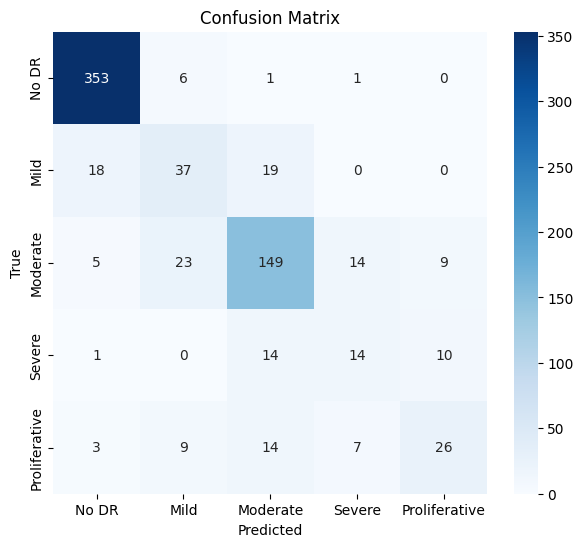

In [40]:
cm = confusion_matrix(test_targets, test_preds)

class_names = ["No DR", "Mild", "Moderate", "Severe", "Proliferative"]

plt.figure(figsize=(7,6))
sns.heatmap(cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=class_names,
            yticklabels=class_names)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")

plt.show()

**ResNet50 Classification Report**

In [41]:
print(classification_report(test_targets, test_preds))

              precision    recall  f1-score   support

           0       0.93      0.98      0.95       361
           1       0.49      0.50      0.50        74
           2       0.76      0.74      0.75       200
           3       0.39      0.36      0.37        39
           4       0.58      0.44      0.50        59

    accuracy                           0.79       733
   macro avg       0.63      0.60      0.61       733
weighted avg       0.78      0.79      0.78       733



**Train and val loss curves**

In [42]:
def plot_training_curves(train_losses, val_losses, train_accs, val_accs, train_qwks, val_qwks, model_name):
    epochs = range(1, len(train_losses) + 1)

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    axes[0].plot(epochs, train_losses, label='Train Loss', marker='o')
    axes[0].plot(epochs, val_losses, label='Val Loss', marker='o')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].set_title(f'{model_name} — Loss Curve')
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].plot(epochs, train_accs, label='Train Acc', marker='o')
    axes[1].plot(epochs, val_accs, label='Val Acc', marker='o')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy')
    axes[1].set_title(f'{model_name} — Accuracy Curve')
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    axes[2].plot(epochs, train_qwks, label='Train QWK', marker='o')
    axes[2].plot(epochs, val_qwks, label='Val QWK', marker='o')
    axes[2].set_xlabel('Epoch')
    axes[2].set_ylabel('QWK')
    axes[2].set_title(f'{model_name} — QWK Curve')
    axes[2].legend()
    axes[2].grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(f'{model_name}_training_curves.png', dpi=150)
    plt.show()

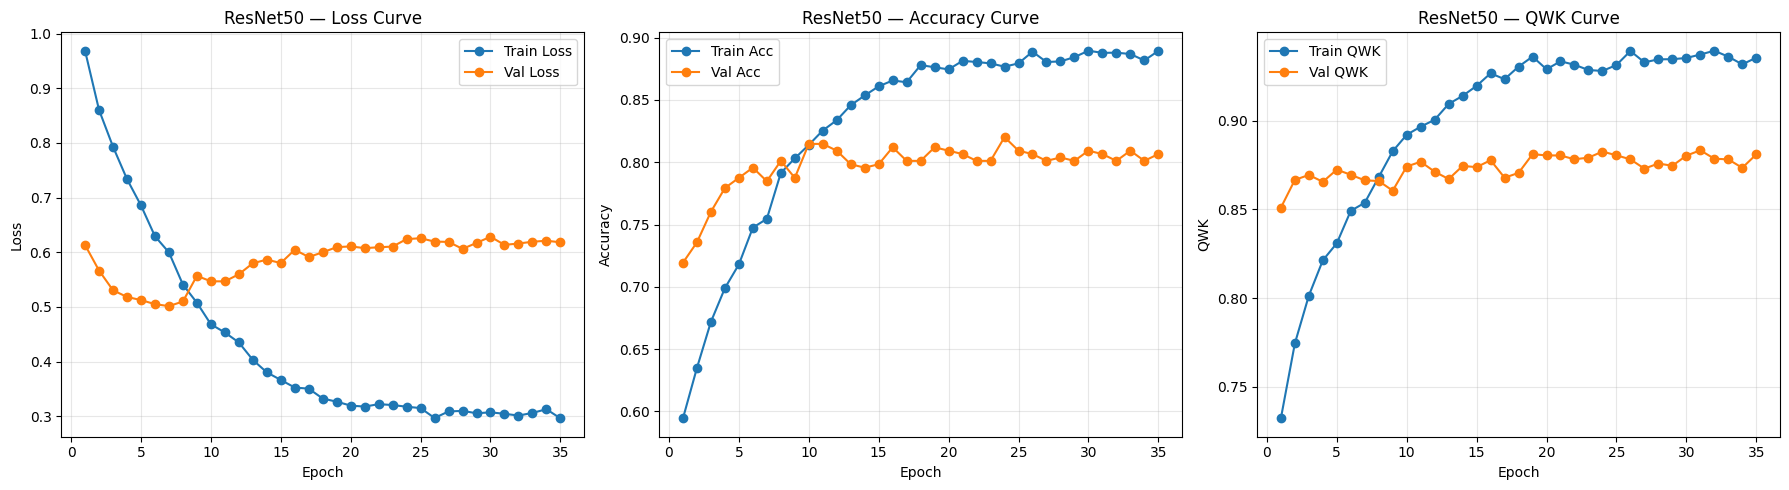

In [43]:
plot_training_curves(train_losses, val_losses, train_accs, val_accs, train_qwks, val_qwks, "ResNet50")